# Station coverage: Kreuzberg vs Wilmersdorf
How well does the network of public transit stations cover each district in the five selected years (1951, 1961, 1967, 1976, 1984)?



## Step 1: Unzip the repository

In [ ]:
import glob

# Find the uploaded zip file and extract it
zips = glob.glob("*.zip")
print("Zip found:", zips)
!unzip -q -o "{zips[0]}"

# BASE is the prefix used for every file path below
BASE = glob.glob("Intro_to_DH_Team6-main*/")[0]
print("Working folder:", BASE)

Zip found: ['Intro_to_DH_Team6-main (1) (1).zip']
Working folder: Intro_to_DH_Team6-main/


## Step 2: Libraries and parameters
`CRS_M` is a coordinate system in **metres** (UTM zone 33N, suited to Berlin). It is needed because a buffer of "500 m" only makes sense in metres, not in degrees.

The radii are 250 m, 500 m and 1000 m. With 1 km every district is 100% covered in every year, so that radius alone does not distinguish anything.

In [ ]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import os

CRS_M = "EPSG:25833"          # metric CRS for Berlin
YEARS = [1951, 1961, 1967, 1976, 1984]
RADII = [250, 500, 1000]      # coverage radii in metres
MAP_RADIUS = 500              # radius used for the main maps

# Output folders
os.makedirs(BASE + "Results", exist_ok=True)
os.makedirs(BASE + "Visualisations", exist_ok=True)

## Step 3: Load the districts
We open the table `a0000000b.gdbtable` directly. It contains the district polygons.

In [ ]:
districts = gpd.read_file(BASE + "Dataset/External/a0000000b.gdbtable")
districts = districts.to_crs(CRS_M)   # reproject from EPSG:3857 to metres

# Keep only the two districts of interest, each as a single polygon
areas = {
    "Kreuzberg": districts[districts["name"] == "Kreuzberg"].geometry.union_all(),
    "Wilmersdorf": districts[districts["name"] == "Wilmersdorf"].geometry.union_all(),
}
for name, poly in areas.items():
    print(name, round(poly.area / 1e6, 2), "km2")

Kreuzberg 10.44 km2
Wilmersdorf 7.16 km2


## Step 4: Load the stations
`stations.csv` has no opening or closing date columns. Each year has its own list of stations, and **the year is the first 4 digits of `stop_id`** (e.g. 194617 = 1946). The `standort` column is "lat, lon" (already identified).

In [ ]:
df = pd.read_csv(BASE + "Dataset/Raw/stations.csv")

# Year = first 4 digits of stop_id
df["year"] = df["stop_id"].astype(str).str[:4].astype(int)

# Split "lat, lon" into two numeric columns
coords = df["standort"].str.split(",", expand=True).astype(float)
df["lat"], df["lon"] = coords[0], coords[1]

# Build point geometries: x = longitude, y = latitude, then convert to metres
stations = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df["lon"], df["lat"]),
    crs="EPSG:4326",
).to_crs(CRS_M)

print(stations.groupby("year").size())

year
1946     632
1951     940
1956    1261
1960    1404
1961    1379
1964    1462
1967    1381
1971    1292
1976    1796
1980    1724
1982    1906
1984    1913
1989    2668
dtype: int64


## Step 5: Compute the coverage
For each year and radius: draw a buffer around **all** Berlin stations of that year (including those outside the district, because they can cover part of it), merge the circles, and intersect the result with the district.

The result shows a table with year, which district , radius, how many total stations used, stations in the district , area of the district and area that is covered with percentage.

In [ ]:
rows, maps = [], {}

for year in YEARS:
    active = stations[stations["year"] == year]
    for r in RADII:
        # Circles around every station, merged into one shape
        covered_all = active.buffer(r).union_all()
        for name, poly in areas.items():
            covered = covered_all.intersection(poly)   # covered part inside the district
            rows.append({
                "year": year,
                "district": name,
                "radius_m": r,
                "stations_total": len(active),
                "stations_inside": int(active.within(poly).sum()),
                "area_km2": poly.area / 1e6,
                "covered_km2": covered.area / 1e6,
                "coverage_pct": covered.area / poly.area * 100,
            })
            maps[(year, name, r)] = covered

result = pd.DataFrame(rows)
result.to_csv(BASE + "Results/coverage_results.csv", index=False)

# Summary table: coverage (%) by district, year and radius
result.pivot_table(index=["district", "year"], columns="radius_m", values="coverage_pct").round(1)

radius_m          250   500    1000
district    year                   
Kreuzberg   1951  37.2  90.4  100.0
            1961  55.4  97.7  100.0
            1967  49.2  97.0  100.0
            1976  60.2  98.6  100.0
            1984  52.9  97.0  100.0
Wilmersdorf 1951  36.5  86.7  100.0
            1961  54.2  98.1  100.0
            1967  47.8  96.2  100.0
            1976  56.8  97.8  100.0
            1984  61.2  97.5  100.0

## Step 6: Maps (2 districts x 5 years)
Grey = not covered, blue = covered, red = stations near the district.

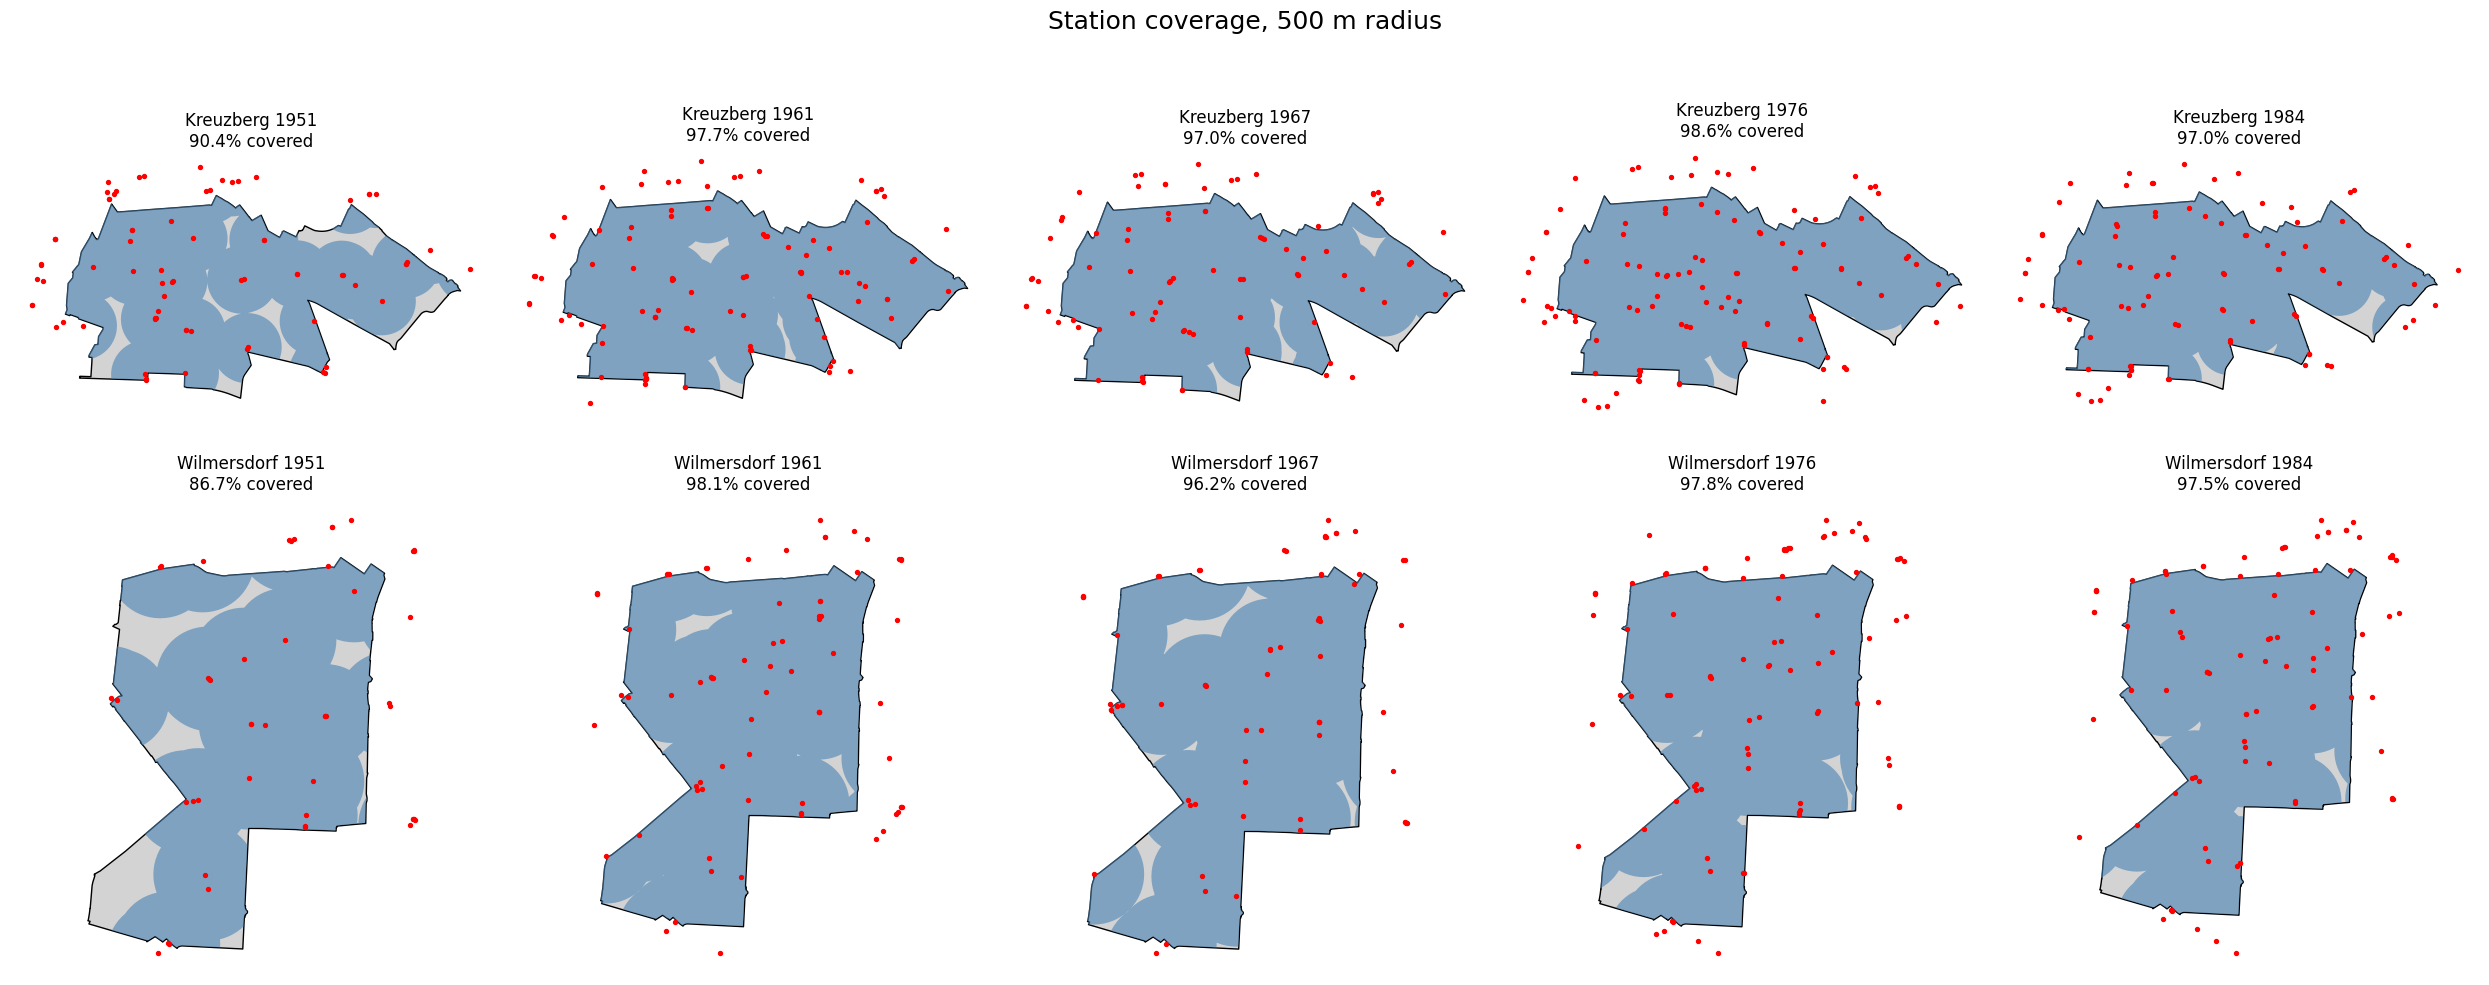

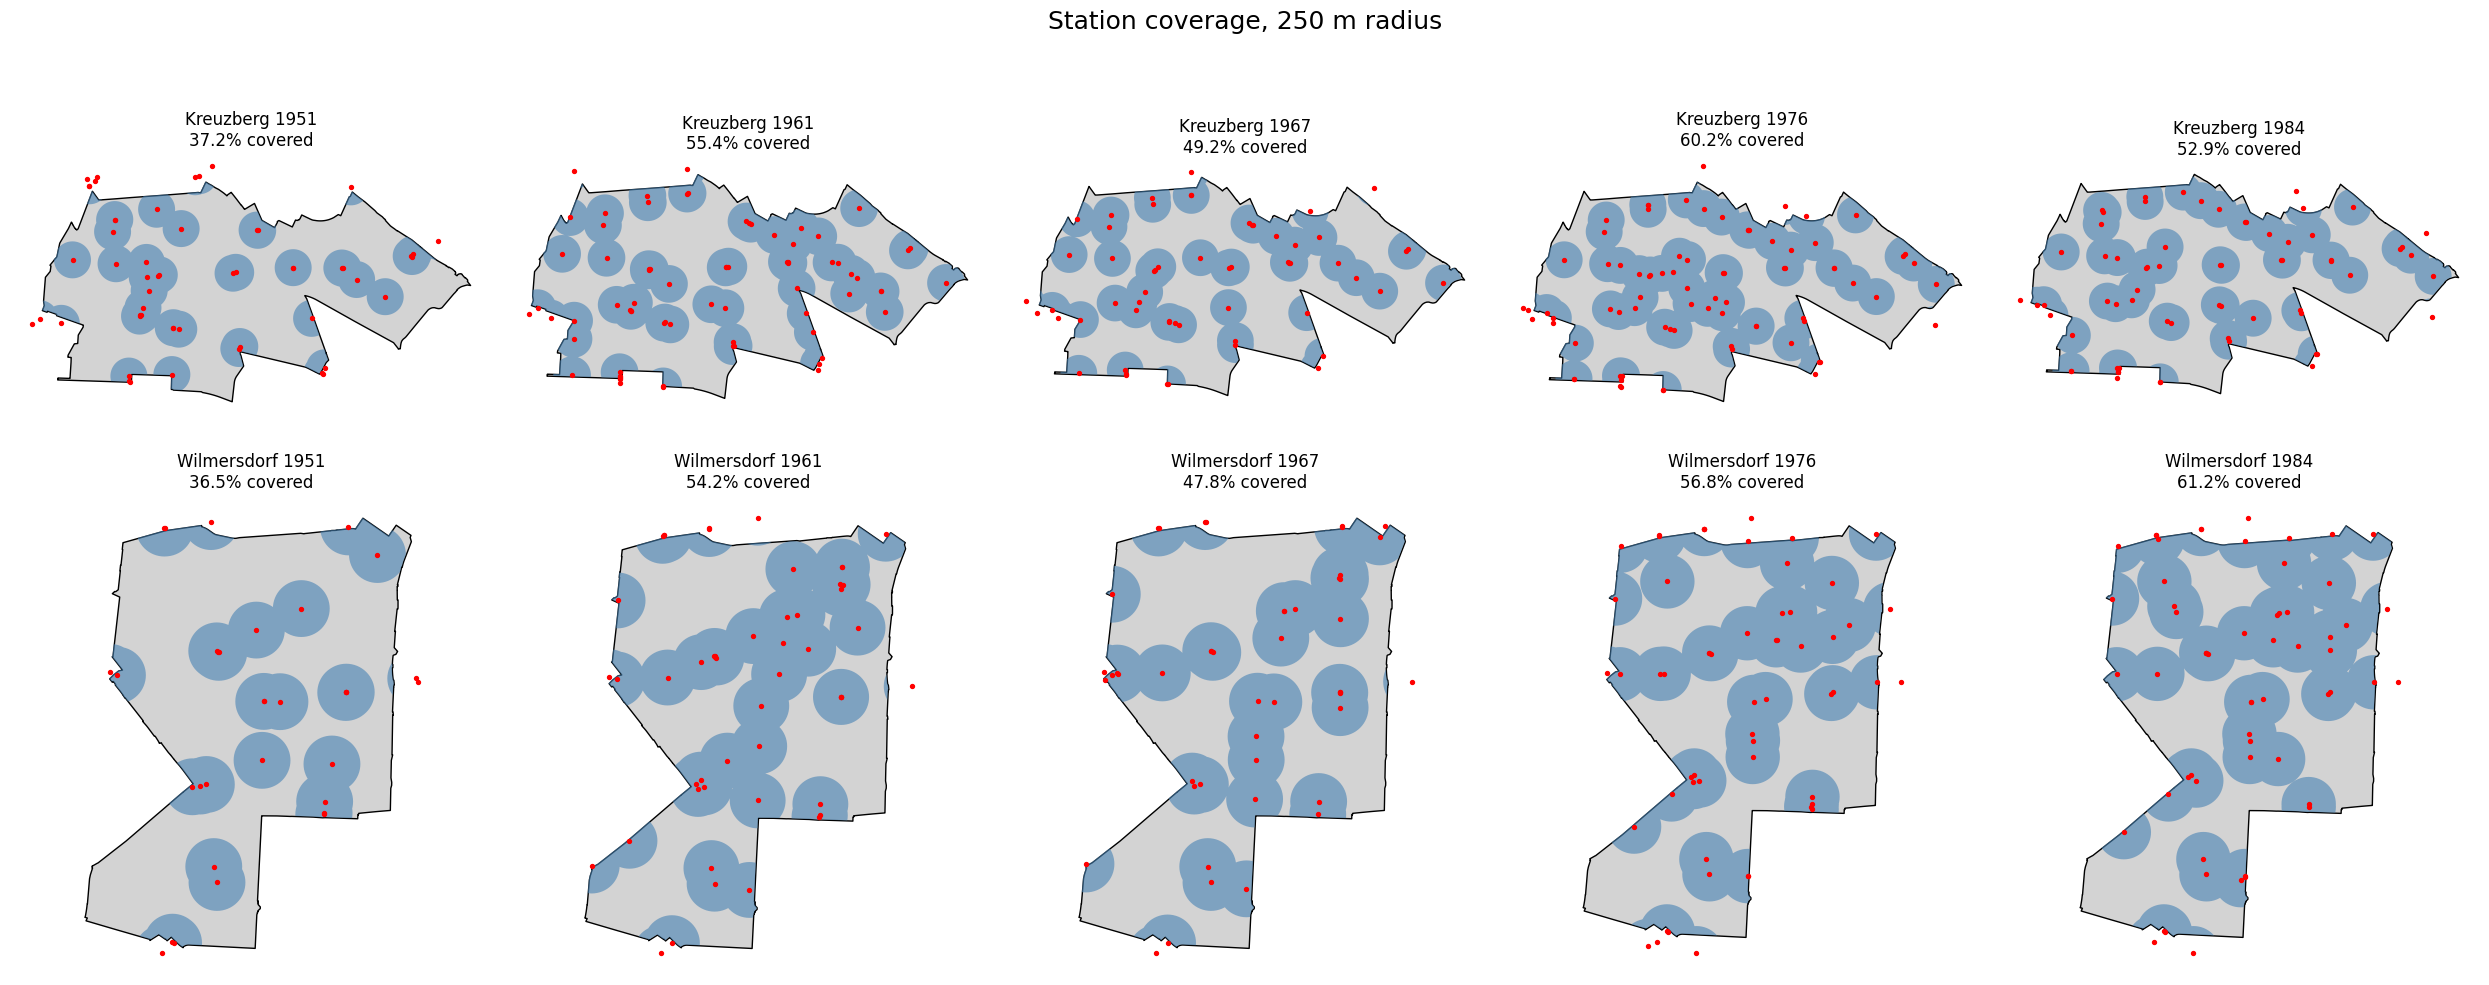

In [ ]:
def draw_maps(r):
    fig, axes = plt.subplots(2, 5, figsize=(25, 10))
    for i, name in enumerate(areas):
        poly = areas[name]
        for j, year in enumerate(YEARS):
            ax = axes[i, j]
            active = stations[stations["year"] == year]
            gpd.GeoSeries([poly]).plot(ax=ax, color="lightgrey", edgecolor="black")
            gpd.GeoSeries([maps[(year, name, r)]]).plot(ax=ax, color="steelblue", alpha=0.6)
            active[active.distance(poly) < r].plot(ax=ax, color="red", markersize=8)
            pct = result[(result.year == year) & (result.district == name) & (result.radius_m == r)]["coverage_pct"].iloc[0]
            ax.set_title(f"{name} {year}\n{pct:.1f}% covered")
            ax.axis("off")
    fig.suptitle(f"Station coverage, {r} m radius", fontsize=18)
    plt.tight_layout()
    plt.savefig(BASE + f"Visualisations/coverage_maps_{r}m.png", dpi=150)
    plt.show()

draw_maps(MAP_RADIUS)
draw_maps(250)

## Step 7: Coverage over time

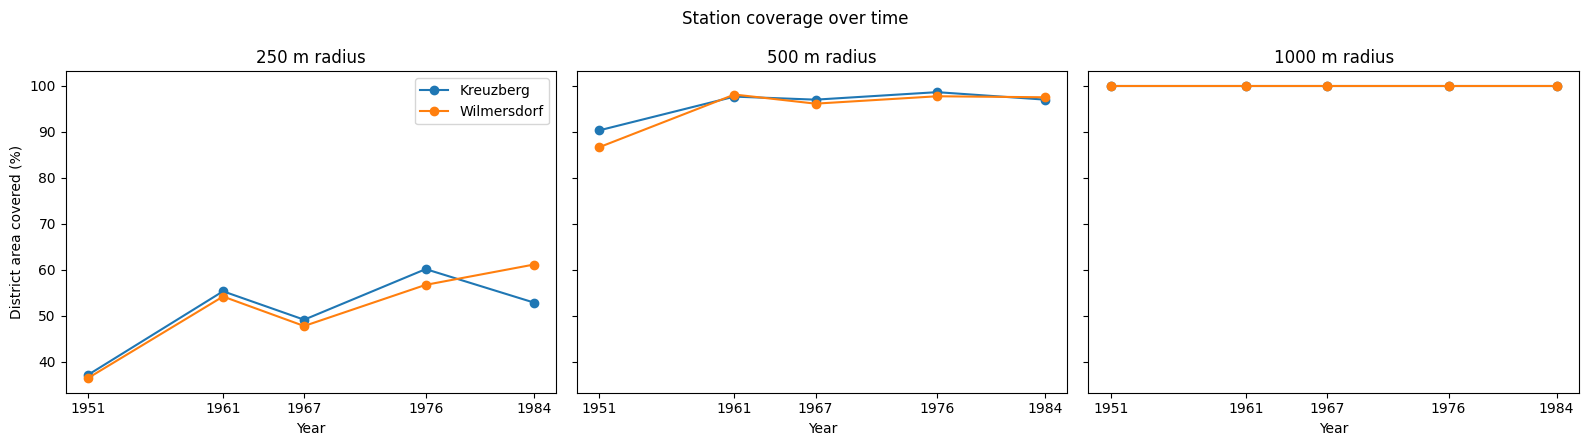

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, r in zip(axes, RADII):
    for name in areas:
        sub = result[(result.district == name) & (result.radius_m == r)]
        ax.plot(sub["year"], sub["coverage_pct"], marker="o", label=name)
    ax.set_title(f"{r} m radius")
    ax.set_xlabel("Year")
    ax.set_xticks(YEARS)
axes[0].set_ylabel("District area covered (%)")
axes[0].legend()
plt.suptitle("Station coverage over time")
plt.tight_layout()
plt.savefig(BASE + "Visualisations/coverage_trend.png", dpi=150)
plt.show()

In [ ]:
result

,year,district,radius_m,stations_total,stations_inside,area_km2,covered_km2,coverage_pct
0,1951,Kreuzberg,250,940,39,10.444626,3.884539,37.191751
1,1951,Wilmersdorf,250,940,23,7.157508,2.612225,36.496284
2,1951,Kreuzberg,500,940,39,10.444626,9.436961,90.352312
3,1951,Wilmersdorf,500,940,23,7.157508,6.205106,86.693666
4,1951,Kreuzberg,1000,940,39,10.444626,10.444626,100.000000
5,1951,Wilmersdorf,1000,940,23,7.157508,7.157508,100.000000
6,1961,Kreuzberg,250,1379,61,10.444626,5.783173,55.369842
7,1961,Wilmersdorf,250,1379,39,7.157508,3.881568,54.230722
8,1961,Kreuzberg,500,1379,61,10.444626,10.202456,97.681393
9,1961,Wilmersdorf,500,1379,39,7.157508,7.023676,98.130179
